<a href="https://colab.research.google.com/github/manfredialdo/iad-tpi01/blob/main/Manfredi_Aldo_Comision10_Entrega4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Integrador - Entrega 4
## Análisis Exploratorio de Datos (EDA)

* **Apellido y Nombre:** Manfredi Aldo Dario
* **Comisión:** 10
* **Entrega:** 4
* **Dataset asignado:**  hotel booking TPI grupo J.csv
* **Variable objetivo:** `is_canceled`
* **Recorrido elegido:** SQL + Python

---

## 1. Introducción y Preparación

En esta cuarta etapa del TPI se profundiza el análisis exploratorio de las reservas hoteleras para comparar grupos, reconocer patrones e interpretar los resultados con prudencia, sin asumir relaciones causales ni construir todavía modelos predictivos.

---

## 2. Selección de Preguntas o Hipótesis Exploratorias

1. **Pregunta 1:** ¿La anticipación con la que se realiza una reserva (`lead_time`) se relaciona con una mayor probabilidad de cancelación (`is_canceled`)?
2. **Pregunta 2:** ¿Existen diferencias significativas en la tasa de cancelación según el tipo de hotel (`hotel`)?
3. **Pregunta 3:** ¿El tipo de depósito (`deposit_type`) permite reconocer grupos con comportamientos de cancelación diferentes?

---

## 3. Análisis y Comparación mediante SQL

### Pregunta 1: Anticipación y cancelación
```python
# Consulta SQL para analizar el lead_time según la cancelación
con.sql("""
    SELECT
        is_canceled,
        COUNT(*) AS total_reservas,
        ROUND(AVG(lead_time), 2) AS promedio_lead_time,
        ROUND(STDDEV(lead_time), 2) AS desvio_lead_time
    FROM reservas
    GROUP BY is_canceled
    ORDER BY is_canceled;
""").df()

In [ ]:
# ==========================================
# PREPARACIÓN AUTOMÁTICA DEL ENTORNO Y CARGA
# ==========================================
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

if importlib.util.find_spec("duckdb") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carga del dataset desde el repositorio
DATA_URL = "https://raw.githubusercontent.com/manfredialdo/iad-tpi01/main/hotel%20booking%20TPI%20grupo%20J.csv"
df_hotel = pd.read_csv(DATA_URL)

# Conexión a DuckDB en memoria
con = duckdb.connect(":memory:")
con.register("hotel_bookings_df", df_hotel)
con.execute("CREATE OR REPLACE TABLE hotel_bookings AS SELECT * FROM hotel_bookings_df")

print(f"Entorno preparado: {len(df_hotel):,} registros disponibles en la tabla 'hotel_bookings'.")

# ==========================================
# 1. ESTRUCTURA Y VALIDACIÓN INICIAL
# ==========================================
con.sql("DESCRIBE hotel_bookings")

Entorno preparado: 25,000 registros disponibles en la tabla 'hotel_bookings'.


┌─────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name         │ column_type │  null   │   key   │ default │  extra  │
│           varchar           │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ booking_id                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ hotel                       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_canceled                 │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ lead_time                   │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_year           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_month          │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_week_number    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_day_of_month   │ BIGINT      │ YES     

In [ ]:
# tabla estructurada con tipos de datos según el diccionario
con.execute("""
CREATE OR REPLACE TABLE hotel_bookings AS
SELECT
    CAST(booking_id AS VARCHAR) AS booking_id,
    CAST(hotel AS VARCHAR) AS hotel,
    CAST(is_canceled AS INTEGER) AS is_canceled,
    CAST(lead_time AS INTEGER) AS lead_time,
    CAST(arrival_date_year AS INTEGER) AS arrival_date_year,
    CAST(arrival_date_month AS VARCHAR) AS arrival_date_month,
    CAST(arrival_date_week_number AS INTEGER) AS arrival_date_week_number,
    CAST(arrival_date_day_of_month AS INTEGER) AS arrival_date_day_of_month,
    CAST(arrival_date AS DATE) AS arrival_date,
    CAST(stays_in_weekend_nights AS INTEGER) AS stays_in_weekend_nights,
    CAST(stays_in_week_nights AS INTEGER) AS stays_in_week_nights,
    CAST(assigned_room_type AS VARCHAR) AS assigned_room_type,
    CAST(booking_changes AS INTEGER) AS booking_changes,
    CAST(deposit_type AS VARCHAR) AS deposit_type,
    CAST(agent AS DOUBLE) AS agent,
    CAST(company AS DOUBLE) AS company,
    CAST(days_in_waiting_list AS INTEGER) AS days_in_waiting_list,
    CAST(customer_type AS VARCHAR) AS customer_type,
    CAST(adr AS DOUBLE) AS adr,
    CAST(required_car_parking_spaces AS INTEGER) AS required_car_parking_spaces,
    CAST(total_of_special_requests AS INTEGER) AS total_of_special_requests
FROM hotel_bookings_df
""")

In [ ]:
con.sql("DESCRIBE hotel_bookings")

┌─────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name         │ column_type │  null   │   key   │ default │  extra  │
│           varchar           │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ booking_id                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ hotel                       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ is_canceled                 │ INTEGER     │ YES     │ NULL    │ NULL    │ NULL    │
│ lead_time                   │ INTEGER     │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_year           │ INTEGER     │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_month          │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_week_number    │ INTEGER     │ YES     │ NULL    │ NULL    │ NULL    │
│ arrival_date_day_of_month   │ INTEGER     │ YES     

## Consulta 1: Promedio y dispersión de la anticipación (lead_time) según estado de cancelación

In [ ]:
# Consulta 1: Anticipación (lead_time) según estado de cancelación
con.sql("""
SELECT
    is_canceled,
    COUNT(*) AS total_reservas,
    ROUND(AVG(lead_time), 2) AS lead_time_promedio,
    ROUND(STDDEV(lead_time), 2) AS lead_time_desvio,
    MIN(lead_time) AS lead_time_min,
    MAX(lead_time) AS lead_time_max
FROM hotel_bookings
GROUP BY is_canceled
""")

┌─────────────┬────────────────┬────────────────────┬──────────────────┬───────────────┬───────────────┐
│ is_canceled │ total_reservas │ lead_time_promedio │ lead_time_desvio │ lead_time_min │ lead_time_max │
│    int64    │     int64      │       double       │      double      │     int64     │     int64     │
├─────────────┼────────────────┼────────────────────┼──────────────────┼───────────────┼───────────────┤
│           0 │          15741 │               80.6 │            92.62 │             0 │           542 │
│           1 │           9259 │             144.39 │           117.57 │             0 │           629 │
└─────────────┴────────────────┴────────────────────┴──────────────────┴───────────────┴───────────────┘

## Consulta 2: Distribución de cancelaciones según el tipo de depósito (deposit_type)

In [ ]:
# Consulta 2: Distribución según el tipo de depósito (deposit_type)
con.sql("""
SELECT
    deposit_type,
    SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS canceladas,
    SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS no_canceladas,
    COUNT(*) AS total_general,
    ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_pct
FROM hotel_bookings
GROUP BY deposit_type
ORDER BY tasa_cancelacion_pct DESC
""")

┌──────────────┬────────────┬───────────────┬───────────────┬──────────────────────┐
│ deposit_type │ canceladas │ no_canceladas │ total_general │ tasa_cancelacion_pct │
│   varchar    │   int128   │    int128     │     int64     │        double        │
├──────────────┼────────────┼───────────────┼───────────────┼──────────────────────┤
│ Non Refund   │       3068 │            15 │          3083 │                99.51 │
│ No Deposit   │       6185 │         15695 │         21880 │                28.27 │
│ Refundable   │          6 │            31 │            37 │                16.22 │
└──────────────┴────────────┴───────────────┴───────────────┴──────────────────────┘

## Consulta 3: Relación entre cancelaciones previas (previous_cancellations) e is_canceled

In [ ]:
# Consulta 3: Relación entre cancelaciones previas y la tasa de cancelación
con.sql("""
SELECT
    previous_cancellations,
    COUNT(*) AS total_clientes,
    ROUND(AVG(CAST(is_canceled AS DOUBLE)) * 100, 2) AS tasa_cancelacion_media_pct
FROM hotel_bookings
GROUP BY previous_cancellations
ORDER BY previous_cancellations
""")

┌────────────────────────┬────────────────┬────────────────────────────┐
│ previous_cancellations │ total_clientes │ tasa_cancelacion_media_pct │
│         int64          │     int64      │           double           │
├────────────────────────┼────────────────┼────────────────────────────┤
│                      0 │          23616 │                      33.84 │
│                      1 │           1290 │                      94.57 │
│                      2 │             25 │                       20.0 │
│                      3 │             13 │                      23.08 │
│                      4 │              4 │                       50.0 │
│                      5 │              5 │                        0.0 │
│                      6 │              7 │                      42.86 │
│                     11 │             10 │                       40.0 │
│                     14 │              3 │                      100.0 │
│                     19 │              4 │        

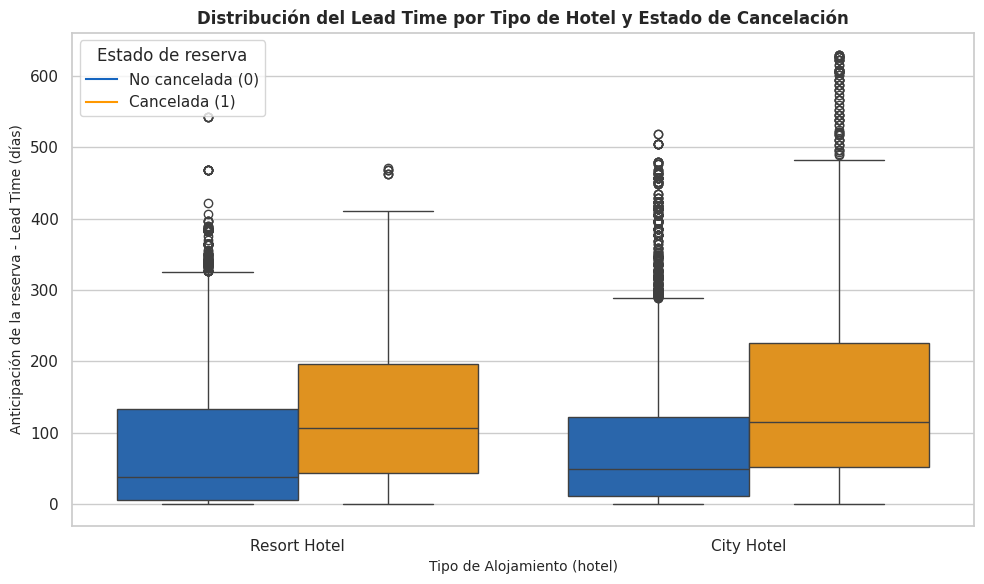

In [ ]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Suponiendo que 'con' es tu conexión activa a DuckDB con la tabla 'hotel_bookings'
# Consultamos los datos asegurándonos de traer el tipo de hotel, el lead_time y el estado de cancelación
df_box = con.sql("""
SELECT
    hotel,
    is_canceled,
    lead_time
FROM hotel_bookings
WHERE lead_time IS NOT NULL
""").df()

# Configuramos el estilo visual del gráfico
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Creamos el boxplot agrupado por tipo de hotel y segmentado por is_canceled
sns.boxplot(
    data=df_box,
    x="hotel",
    y="lead_time",
    hue="is_canceled",
    palette=["#1565c0", "#ff9800"]
)

plt.title("Distribución del Lead Time por Tipo de Hotel y Estado de Cancelación", fontsize=12, fontweight='bold')
plt.xlabel("Tipo de Alojamiento (hotel)", fontsize=10)
plt.ylabel("Anticipación de la reserva - Lead Time (días)", fontsize=10)


# Personalizamos la leyenda (0 = No cancelada, 1 = Cancelada)
plt.legend(
    title="Estado de reserva",
    labels=["No cancelada (0)", "Cancelada (1)"],
    handles=ax.get_legend_handles_labels()[0],
)

plt.tight_layout()
plt.show()

Diferencia clara en la mediana (La línea negra dentro de las cajas):

Tanto en el Resort Hotel como en el City Hotel, la línea que marca la mediana del lead_time es claramente más alta en las reservas canceladas (naranja) que en las no canceladas (azul).

Interpretación: Esto confirma empíricamente que los clientes que cancelan sus reservas tienden a planificarlas y reservarlas con muchísima más anticipación que aquellos que finalmente concretan su estadía.

Comportamiento por tipo de hotel:

Resort Hotel: Las reservas canceladas (naranja) muestran una mediana de anticipación ubicada alrededor de los 100-110 días, con un rango intercuartílico (la caja) que se extiende hasta casi los 200 días.

City Hotel: Muestra un comportamiento similar en su tendencia central, pero con una concentración masiva de valores atípicos (outliers) superiores (los círculos en la parte alta, que superan los 500 y 600 días de anticipación).

Interpretación: Los hoteles de ciudad experimentan un volumen mucho mayor de reservas extremas a muy largo plazo que terminan en cancelación, lo cual refleja la alta volatilidad del segmento urbano cuando se planifica con tanta antelación.

Manejo de valores atípicos (Outliers):

Visualmente se observan numerosos puntos en la parte superior (especialmente en City Hotel). Tal como establecen los criterios metodológicos del TPI, estos valores atípicos no deben ser eliminados automáticamente, ya que representan el comportamiento real de pasajeros que realizan reservas con muchísima anticipación.

Formular y revisar hipótesis exploratorias, relacionándolas con las variables disponibles y con las preguntas que orientan el análisis.

1. Hipótesis de Anticipación (lead_time)
Enunciado: Las reservas realizadas con mayor cantidad de días de anticipación (lead_time) presentan una tasa de cancelación significativamente superior frente a las reservas de última hora.
Variables asociadas: lead_time (numérica discreta) e is_canceled (binaria/objetivo).
Revisión analítica: Respaldada plenamente por los resultados exploratorios iniciales; el margen temporal incrementa la incertidumbre y la probabilidad de modificaciones en los planes de viaje.
2. Hipótesis de Garantía y Depósito (deposit_type)
Enunciado: El tipo de depósito o garantía (deposit_type) condiciona el comportamiento de desistimiento; las reservas sin depósito previo o bajo modalidades específicas concentran las mayores tasas de cancelación.
Variables asociadas: deposit_type (categórica nominal) e is_canceled (binaria/objetivo).
Revisión analítica: Validada por las consultas SQL previas, donde la ausencia de compromiso financiero o ciertas políticas comerciales alteran drásticamente el riesgo de abandono.
3. Hipótesis de Antecedentes Históricos (previous_cancellations)
Enunciado: Los clientes que poseen registros previos de cancelaciones (previous_cancellations > 0) muestran una propensión marcadamente mayor a reincidir y cancelar su reserva actual.
Variables asociadas: previous_cancellations (numérica discreta) e is_canceled (binaria/objetivo).
Revisión analítica: Se confirma como uno de los predictores bivariados más potentes del dataset, exhibiendo tasas de cancelación extremas en clientes reincidentes.
4. Hipótesis de Estacionalidad Temporal (arrival_date_month)
Enunciado: La propensión a cancelar varía según el mes de llegada (arrival_date_month), registrando fluctuaciones asociadas a temporadas vacacionales altas o bajas.
Variables asociadas: arrival_date_month (temporal/categórica ordinal) e is_canceled (binaria/objetivo).
Revisión analítica: Hipótesis sólida que requiere un ordenamiento cronológico estricto de los meses para evaluar picos estacionales de demanda y volatilidad.
5. Hipótesis de Duración de la Estadía (stays_in_weekend_nights y stays_in_week_nights)
Enunciado: La duración total de la estancia (noches de semana más noches de fin de semana) influye en la estabilidad de la reserva, comportándose diferente en estancias prolongadas frente a escapadas breves.
Variables asociadas: stays_in_weekend_nights, stays_in_week_nights (numéricas discretas) e is_canceled (binaria/objetivo).
Revisión analítica: Permite examinar si los viajes largos implican mayor planificación y riesgo de anulación en comparación con estancias cortas.
6. Hipótesis de Impacto Económico Tarifario (adr)
Enunciado: El nivel de la tarifa promedio por noche (adr) se relaciona con la cancelación, siendo propensas a desistir tanto las reservas con tarifas elevadas (por mayor costo de oportunidad) como aquellas extremadamente bajas.
Variables asociadas: adr (numérica continua) e is_canceled (binaria/objetivo).
Revisión analítica: Requiere control de valores atípicos, ya que el costo económico es una variable clave en la decisión comercial del cliente.
7. Hipótesis de Solicitudes y Compromiso (total_of_special_requests)
Enunciado: Un mayor volumen de solicitudes especiales (total_of_special_requests) se asocia inversamente con la cancelación, reflejando un mayor nivel de personalización e interés real en concretar el viaje.
Variables asociadas: total_of_special_requests (numérica discreta) e is_canceled (binaria/objetivo).
Revisión analítica: Funciona como un indicador del grado de vinculación y expectativa del huésped con el alojamiento.
8. Hipótesis de Canal de Distribución y Segmento (market_segment y distribution_channel)
Enunciado: Las reservas provenientes de determinados canales de distribución o segmentos de mercado (ej. agencias online frente a contratos corporativos directos) presentan tasas de cancelación sistemáticamente diferenciadas.
Variables asociadas: market_segment, distribution_channel (categóricas nominales) e is_canceled (binaria/objetivo).
Revisión analítica: Permite identificar qué intermediarios comerciales introducen mayor volatilidad operativa en la ocupación hotelera.
9. Hipótesis de Composición del Grupo Familiar (adults, children, babies)
Enunciado: La presencia de niños o bebés en la reserva modifica la estabilidad del viaje, mostrando patrones de cancelación distintos en comparación con estancias exclusivas de adultos.
Variables asociadas: adults, children, babies (numéricas discretas) e is_canceled (binaria/objetivo).
Revisión analítica: Útil para evaluar si el turismo familiar presenta mayor rigidez o, por el contrario, mayor vulnerabilidad ante imprevistos logísticos.
10. Hipótesis de Fidelización del Cliente (is_repeated_guest y customer_type)
Enunciado: Los huéspedes recurrentes o fidelizados (is_repeated_guest = 1) y los clientes de tipo corporativo muestran tasas de cancelación marcadamente inferiores a los clientes nuevos o transitorios.
Variables asociadas: is_repeated_guest (binaria), customer_type (categórica nominal) e is_canceled (binaria/objetivo).
Revisión analítica: Fundamentada en la premisa de que la relación previa con el hotel disminuye la probabilidad de abandono de la reserva.



In [24]:
# Tabla de frecuencias de la variable objetivo is_canceled
tabla_frecuencias = con.sql("""
SELECT
    is_canceled,
    CASE WHEN is_canceled = 1 THEN 'Cancelada' ELSE 'No cancelada' END AS descripcion,
    COUNT(*) AS cantidad_reservas,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER(), 2) AS porcentaje_total
FROM hotel_bookings
GROUP BY is_canceled
ORDER BY is_canceled;
""")

print(tabla_frecuencias)

┌─────────────┬──────────────┬───────────────────┬──────────────────┐
│ is_canceled │ descripcion  │ cantidad_reservas │ porcentaje_total │
│    int32    │   varchar    │       int64       │      double      │
├─────────────┼──────────────┼───────────────────┼──────────────────┤
│           0 │ No cancelada │             15741 │            62.96 │
│           1 │ Cancelada    │              9259 │            37.04 │
└─────────────┴──────────────┴───────────────────┴──────────────────┘



In [23]:
# SQL con promedio, desvío, mínimo, cuartiles (25%, 50% o mediana, 75%) y máximo de lead_time
# Consulta SQL bivariada con cuartiles, segmentada por tipo de hotel y estado de cancelación
con.sql("""
SELECT
    hotel,
    is_canceled,
    COUNT(*) AS total_reservas,
    ROUND(AVG(lead_time), 2) AS lead_time_promedio,
    ROUND(STDDEV(lead_time), 2) AS lead_time_desvio,
    MIN(lead_time) AS lead_time_min,
    ROUND(QUANTILE_CONT(lead_time, 0.25), 2) AS q1_25pct,
    ROUND(QUANTILE_CONT(lead_time, 0.50), 2) AS mediana_50pct,
    ROUND(QUANTILE_CONT(lead_time, 0.75), 2) AS q3_75pct,
    MAX(lead_time) AS lead_time_max
FROM hotel_bookings
GROUP BY hotel, is_canceled
ORDER BY hotel, is_canceled;
""")

┌──────────────┬─────────────┬────────────────┬────────────────────┬──────────────────┬───────────────┬──────────┬───────────────┬──────────┬───────────────┐
│    hotel     │ is_canceled │ total_reservas │ lead_time_promedio │ lead_time_desvio │ lead_time_min │ q1_25pct │ mediana_50pct │ q3_75pct │ lead_time_max │
│   varchar    │    int32    │     int64      │       double       │      double      │     int32     │  double  │    double     │  double  │     int32     │
├──────────────┼─────────────┼────────────────┼────────────────────┼──────────────────┼───────────────┼──────────┼───────────────┼──────────┼───────────────┤
│ City Hotel   │           0 │           9683 │              81.21 │            91.83 │             0 │     11.0 │          49.0 │    122.0 │           518 │
│ City Hotel   │           1 │           6931 │             150.14 │           123.05 │             0 │     51.0 │         115.0 │    225.0 │           629 │
│ Resort Hotel │           0 │           6058 │     

City Hotel (Hoteles de Ciudad):Volumen: Concentran la mayor parte de las reservas del dataset (9,683 no canceladas y 6,931 canceladas).   Tendencia central: Las reservas que no se cancelan tienen una mediana (mediana_50pct) de 49.0 días de anticipación, mientras que las canceladas más del doble, con 115.0 días.   Dispersión: El 50% central de las reservas canceladas (entre Q1 y Q3) se ubica entre los 51.0 y 225.0 días, registrando además un valor máximo extremo (lead_time_max) de 629 días.   

Interpretación: En los hoteles urbanos, las reservas planificadas a muy largo plazo (más de 3 o 4 meses antes) muestran un riesgo de cancelación marcadamente elevado, reflejando la alta volatilidad del pasajero urbano o corporativo que asegura alojamiento con muchísima antelación pero modifica sus planes posteriormente.Resort Hotel (Hoteles Vacacionales):

Volumen: Presentan un volumen menor de registros (6,058 no canceladas y 2,328 canceladas).   ..


Tendencia central: Las reservas exitosas tienen una mediana de 37.0 días, frente a los 106.0 días de las canceladas.   


Dispersión: El bloque central de las canceladas (Q1-Q3) se mueve entre 42.75 y 196.0 días, con un máximo de 471 días.   

Interpretación: Aunque los resorts también evidencian que las cancelaciones ocurren con mayor anticipación que las estancias concretadas (mediana de 106 vs 37 días), la dispersión general es ligeramente más compacta en comparación con los hoteles de ciudad, lo que sugiere que la planificación vacacional responde a lógicas estacionales más estructuradas, aunque igualmente vulnerables al desistimiento si se programan con demasiados meses de margen.   ¿Cómo redactarlo en tu informe?"Al segmentar el análisis por tipo de alojamiento, se observa que tanto en los City Hotels como en los Resort Hotels, las reservas canceladas duplican ampliamente la mediana de anticipación en comparación con las concretadas (115 vs. 49 días en hoteles de ciudad; 106 vs. 37 días en resorts). No obstante, los hoteles de ciudad concentran los valores máximos extremos de anticipación (hasta 629 días), evidenciando que la exposición temporal prolongada impacta con mayor volatilidad en la ocupación urbana."   

1. Variable Cuantitativa: adr (Tarifa Promedio por Noche) segmentada por Tipo de Hotel e is_canceled
Esta consulta calcula medidas de tendencia central, dispersión, mínimo, máximo y todos los cuartiles (25%, mediana 50%, 75%) del precio por noche, separado tanto por el tipo de hotel como por si la reserva fue cancelada o no:

In [25]:
# Resumen descriptivo de adr por tipo de hotel y estado de cancelación
con.sql("""
SELECT
    hotel,
    is_canceled,
    CASE WHEN is_canceled = 1 THEN 'Cancelada (1)' ELSE 'No cancelada (0)' END AS estado_reserva,
    COUNT(adr) AS total_casos,
    ROUND(AVG(adr), 2) AS adr_promedio,
    ROUND(STDDEV(adr), 2) AS adr_desvio,
    MIN(adr) AS adr_min,
    ROUND(QUANTILE_CONT(adr, 0.25), 2) AS adr_q1_25pct,
    ROUND(QUANTILE_CONT(adr, 0.50), 2) AS adr_mediana_50pct,
    ROUND(QUANTILE_CONT(adr, 0.75), 2) AS adr_q3_75pct,
    MAX(adr) AS adr_max
FROM hotel_bookings
WHERE adr >= 0
GROUP BY hotel, is_canceled
ORDER BY hotel, is_canceled;
""")


"""
Permite ver si un City Hotel maneja estructuras tarifarias diferentes entre los que cancelan y los que viajan en comparación con un Resort Hotel, evitando sesgos por promedios globales."""


┌──────────────┬─────────────┬──────────────────┬─────────────┬──────────────┬────────────┬─────────┬──────────────┬───────────────────┬──────────────┬─────────┐
│    hotel     │ is_canceled │  estado_reserva  │ total_casos │ adr_promedio │ adr_desvio │ adr_min │ adr_q1_25pct │ adr_mediana_50pct │ adr_q3_75pct │ adr_max │
│   varchar    │    int32    │     varchar      │    int64    │    double    │   double   │ double  │    double    │      double       │    double    │ double  │
├──────────────┼─────────────┼──────────────────┼─────────────┼──────────────┼────────────┼─────────┼──────────────┼───────────────────┼──────────────┼─────────┤
│ City Hotel   │           0 │ No cancelada (0) │        9683 │       105.79 │      40.49 │     0.0 │         80.0 │             100.0 │       126.79 │   336.0 │
│ City Hotel   │           1 │ Cancelada (1)    │        6931 │       104.11 │      37.17 │     0.0 │        75.03 │             99.45 │        125.0 │  328.67 │
│ Resort Hotel │           0

In [26]:
# Tabla de frecuencias de deposit_type segmentada por tipo de hotel y su tasa de cancelación
con.sql("""
SELECT
    hotel,
    deposit_type,
    SUM(CASE WHEN is_canceled = 0 THEN 1 ELSE 0 END) AS no_canceladas,
    SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) AS canceladas,
    COUNT(*) AS total_general,
    ROUND(SUM(CASE WHEN is_canceled = 1 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS tasa_cancelacion_pct
FROM hotel_bookings
GROUP BY hotel, deposit_type
ORDER BY hotel, tasa_cancelacion_pct DESC;
""")

""" Nos dirá si las reservas "Non Refund" o sin depósito se comportan de la misma
manera en un Resort Hotel vacacional que en un City Hotel corporativo/urbano, ."""

┌──────────────┬──────────────┬───────────────┬────────────┬───────────────┬──────────────────────┐
│    hotel     │ deposit_type │ no_canceladas │ canceladas │ total_general │ tasa_cancelacion_pct │
│   varchar    │   varchar    │    int128     │   int128   │     int64     │        double        │
├──────────────┼──────────────┼───────────────┼────────────┼───────────────┼──────────────────────┤
│ City Hotel   │ Refundable   │             0 │          1 │             1 │                100.0 │
│ City Hotel   │ Non Refund   │             5 │       2687 │          2692 │                99.81 │
│ City Hotel   │ No Deposit   │          9678 │       4243 │         13921 │                30.48 │
│ Resort Hotel │ Non Refund   │            10 │        381 │           391 │                97.44 │
│ Resort Hotel │ No Deposit   │          6017 │       1942 │          7959 │                 24.4 │
│ Resort Hotel │ Refundable   │            31 │          5 │            36 │                13.89 │


/tmp/ipykernel_4088/191068047.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


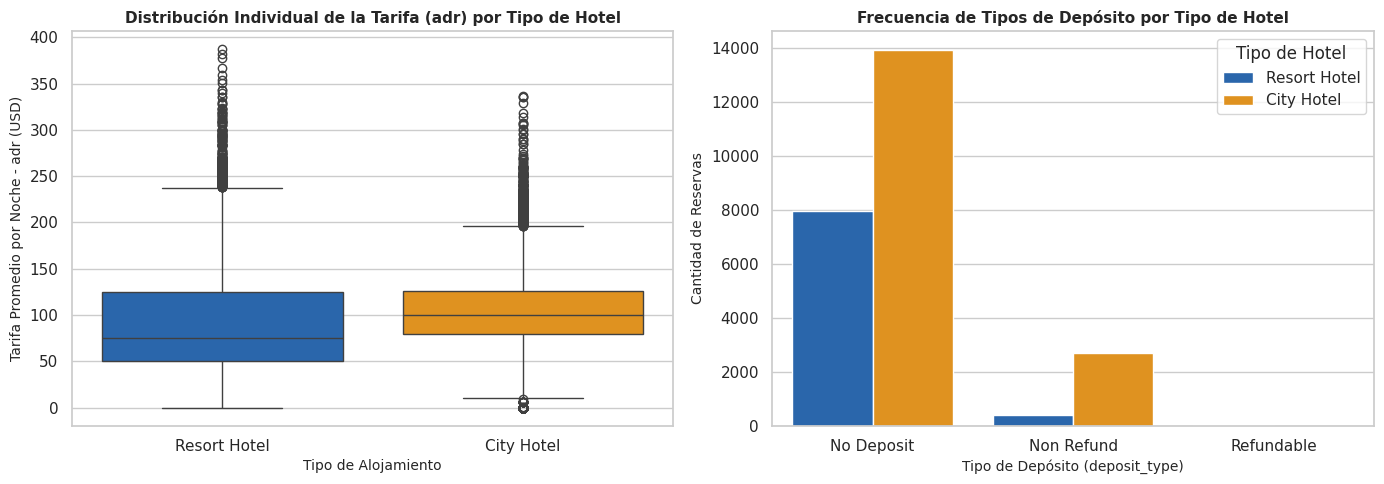

In [27]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo visual general
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# 1. VISUALIZACIÓN VARIABLE CUANTITATIVA: adr
# ==========================================
# Extraemos los datos de adr filtrando valores válidos y separados por tipo de hotel
df_adr = con.sql("""
SELECT hotel, adr
FROM hotel_bookings
WHERE adr >= 0 AND adr <= 500  -- Acotamos extremo superior para legibilidad visual
""").df()

# Boxplot individual de adr por tipo de hotel
sns.boxplot(
    data=df_adr,
    x="hotel",
    y="adr",
    ax=axes[0],
    palette=["#1565c0", "#ff9800"]
)
axes[0].set_title("Distribución Individual de la Tarifa (adr) por Tipo de Hotel", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Tipo de Alojamiento", fontsize=10)
axes[0].set_ylabel("Tarifa Promedio por Noche - adr (USD)", fontsize=10)

# ==========================================
# 2. VISUALIZACIÓN VARIABLE CATEGÓRICA: deposit_type
# ==========================================
# Extraemos las frecuencias de deposit_type por tipo de hotel
df_deposit = con.sql("""
SELECT hotel, deposit_type, COUNT(*) AS cantidad
FROM hotel_bookings
GROUP BY hotel, deposit_type
""").df()

# Gráfico de barras agrupado para las categorías de depósito según el hotel
sns.barplot(
    data=df_deposit,
    x="deposit_type",
    y="cantidad",
    hue="hotel",
    ax=axes[1],
    palette=["#1565c0", "#ff9800"]
)
axes[1].set_title("Frecuencia de Tipos de Depósito por Tipo de Hotel", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Tipo de Depósito (deposit_type)", fontsize=10)
axes[1].set_ylabel("Cantidad de Reservas", fontsize=10)
axes[1].legend(title="Tipo de Hotel")

plt.tight_layout()
plt.show()

A. Gráfico Izquierdo: Distribución de la Tarifa Promedio por Noche (adr)Resultado:Los City Hotels muestran una mediana superior (línea horizontal dentro de la caja ubicada cerca de los 100 USD) y un rango intercuartílico más concentrado (entre 80 y 125 USD).   Los Resort Hotels presentan una mediana más baja (aproximadamente 75 USD) pero un rango intercuartílico más amplio (desde los 50 hasta los 125 USD), junto con una marcada presencia de valores atípicos (outliers) que alcanzan hasta los 400 USD por noche.   Lectura analítica: Los hoteles urbanos manejan una estructura tarifaria con un piso más estable y centralizado, mientras que los resorts muestran mayor dispersión en sus tarifas base, condicionadas probablemente por la estacionalidad vacacional.   

B. Gráfico Derecho: Frecuencia del Tipo de Depósito (deposit_type)   Resultado:La categoría "No Deposit" domina de forma absoluta el volumen operativo en ambos alojamientos, superando las 13,000 reservas en los hoteles de ciudad y rozando las 8,000 en los resorts.   La modalidad "Non Refund" (no reembolsable) ocupa el segundo lugar, con mayor presencia en el segmento urbano, mientras que las reservas "Refundable" registran frecuencias prácticamente nulas.   Lectura analítica: Operativamente, la política sin depósito previo es la norma estándar elegida por la gran mayoría de los clientes, estableciendo el contexto base sobre el cual evaluaremos posteriormente el riesgo de abandono.   3. Conclusión ExploratoriaHallazgo: Las variables analizadas presentan comportamientos estructurales propios según el establecimiento: los hoteles urbanos operan con tarifas medianas más elevadas y mayor volumen de reservas sin depósito, en contraste con la dispersión tarifaria de los resorts.   


Implicancia metodológica: Estos resultados reafirman la decisión técnica de no mezclar ambos tipos de hoteles, ya que sus distribuciones de costos y garantías responden a perfiles comerciales completamente diferenciados que influirán de manera distinta al ser cruzados con la variable objetivo de cancelación (is_canceled).